# Predicting Used Car Prices in Pakistan

Our objective is to estimate asking prices in lakh PKR, not confirmed sale prices.

In [1]:
import pandas as pd, numpy as np, matplotlib.pyplot as plt, json, joblib
from pathlib import Path
from sklearn.model_selection import train_test_split, KFold, cross_val_score
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, OrdinalEncoder, StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.pipeline import make_pipeline
from sklearn.dummy import DummyRegressor
from sklearn.linear_model import LinearRegression, Ridge, Lasso, ElasticNet
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import RandomForestRegressor, ExtraTreesRegressor, HistGradientBoostingRegressor, GradientBoostingRegressor, AdaBoostRegressor
from sklearn.neighbors import KNeighborsRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from sklearn.base import clone
from sklearn.inspection import permutation_importance
Path('results').mkdir(exist_ok=True)
raw=pd.read_csv('pakwheels.csv')
print(raw.shape, 'Duplicate URLs:',raw.ad_url.duplicated().sum())
display(raw.drop(columns=['description','car_features']).head())
display(pd.DataFrame({'missing':raw.isna().sum(),'dtype':raw.dtypes.astype(str),'unique':raw.nunique()}))

(89956, 17) Duplicate URLs: 0


,Unnamed: 0,ad_url,title,location,model_year,price,mileage,engine_type,transmission,registered_in,color,assembly,engine_capacity,body_type,ad_last_updated
0,0,https://www.pakwheels.com/used-cars/honda-civi...,Honda Civic VTi Oriel Prosmatec 1.8 i-VTEC 2007,Islamabad Islamabad,2007.0,PKR 16.5 lacs,"100,000 km",Petrol,Automatic,Lahore,Grey,Imported Cars,1800 cc,Sedan,"Oct 09, 2022"
1,1,https://www.pakwheels.com/used-cars/suzuki-meh...,Suzuki Mehran VX Euro II 2012,"Eden Gardens, Faisalabad Punjab",2012.0,PKR 7 lacs,"100,000 km",Petrol,Manual,Faisalabad,Grey,Imported Cars,800 cc,Hatchback,"Oct 09, 2022"
2,2,https://www.pakwheels.com/used-cars/honda-civi...,Honda Civic EX 1995,"Bostan Road, Rawalpindi Punjab",1995.0,PKR 7.6 lacs,999 km,Petrol,Manual,Lahore,Black,Imported Cars,1500 cc,Sedan,"Oct 09, 2022"
3,3,https://www.pakwheels.com/used-cars/toyota-for...,Toyota Fortuner 2.7 VVTi 2013,"Kallar Kahar Road, Chakwal Punjab",2013.0,PKR 70 lacs,"94,000 km",Petrol,Automatic,Lahore,Black,Imported Cars,2700 cc,SUV,"Oct 09, 2022"
4,4,https://www.pakwheels.com/used-cars/suzuki-meh...,Suzuki Mehran VX Euro II 2015,Muzaffar Gargh Punjab,2015.0,PKR 8 lacs,"86,000 km",Petrol,Manual,Multan,Grey,Imported Cars,796 cc,Hatchback,"Oct 09, 2022"


,missing,dtype,unique
Unnamed: 0,0,int64,89956
ad_url,0,object,89956
title,0,object,9852
location,2,object,2416
model_year,2507,float64,33
price,2,object,2224
mileage,2,object,9609
engine_type,955,object,3
transmission,2,object,2
registered_in,2,object,145


## A. Data preparation
Prices on request are not valid regression labels. Convert crore to 100 lakh. Recover missing years from titles within the observed range. Do not discard luxury listings merely for being expensive. A mileage of 1 km may be a placeholder; flag it. Descriptions can contain the asking price, so exclude them to prevent leakage. Seller identity and condition cannot be verified.

In [2]:
d=raw.copy()
p=d.price.str.lower().str.extract(r'^pkr\s*([\d,.]+)\s*(lacs|crore)$')
d['target']=pd.to_numeric(p[0].str.replace(',',''),errors='coerce')*p[1].map({'lacs':1,'crore':100})
print('Invalid/nonpositive price:',(~(d.target>0)).sum())
d=d[d.target>0].copy()
yr=pd.to_numeric(d.title.str.extract(r'((?:19|20)\d{2})\s*$')[0],errors='coerce').where(lambda x:x.between(1990,2022))
recovered=int((d.model_year.isna()&yr.notna()).sum()); d['age']=2022-d.model_year.fillna(yr)
for col in ['mileage','engine_capacity']:
    d[col]=pd.to_numeric(d[col].str.replace(',','').str.extract(r'(\d+)')[0],errors='coerce')
d['low_mileage']=d.mileage.le(1).astype(int)
d['make']=d.title.str.lower().str.split().str[0]; d['model']=d.title.str.lower().str.split().str[:2].str.join(' ')
d['region']=d.location.str.split(',').str[-1].str.strip()
d['feature_count']=d.car_features.fillna('').map(str.splitlines).map(len)
d['features_missing']=d.car_features.isna().astype(int)
for f in ['ABS','Air Bags','Air Conditioning','Sun Roof','Power Steering']:
    d[f]=d.car_features.fillna('').str.contains(f,regex=False).astype(int)
nums=['age','mileage','engine_capacity','low_mileage','feature_count','features_missing','ABS','Air Bags','Air Conditioning','Sun Roof','Power Steering']
cats=['make','model','region','engine_type','transmission','registered_in','color','assembly','body_type']
for col in cats: d[col]=d[col].str.strip().str.lower()
# Remove indistinguishable feature/price rows to reduce repeated-listing leakage.
before=len(d); d=d.drop_duplicates(nums+cats+['target']); print('Recovered years:',recovered,'Removed duplicates:',before-len(d),'Clean rows:',len(d),'Low mileage flags:',d.low_mileage.sum())
display(d.target.describe(percentiles=[.01,.5,.95,.99]))

Invalid/nonpositive price: 1410


Recovered years: 0 Removed duplicates: 692 Clean rows: 87854 Low mileage flags: 1760


count    87854.000000
mean        30.399372
std         40.311547
min          1.000000
1%           2.800000
50%         21.500000
95%         78.000000
99%        170.000000
max       1150.000000
Name: target, dtype: float64

## B. Exploratory analysis
Median prices are less sensitive to expensive outliers than means. Rank correlations capture monotonic relationships. Age replaces model year to avoid redundant predictors.

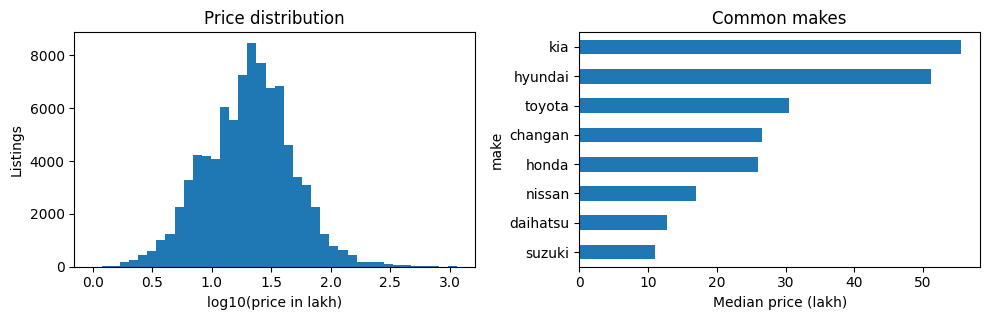

target              1.000000
feature_count       0.756171
ABS                 0.679474
Air Bags            0.650513
Power Steering      0.560785
engine_capacity     0.552524
Sun Roof            0.393003
Air Conditioning    0.322351
low_mileage         0.048669
features_missing   -0.174937
mileage            -0.333565
age                -0.665874
Name: target, dtype: float64

make
daihatsu   -0.284013
honda      -0.592246
kia        -0.239584
suzuki     -0.333667
toyota     -0.475473
dtype: float64

In [3]:
fig,ax=plt.subplots(1,2,figsize=(10,3.3)); ax[0].hist(np.log10(d.target),bins=40); ax[0].set(xlabel='log10(price in lakh)',ylabel='Listings',title='Price distribution')
top=d.make.value_counts().head(8).index
d[d.make.isin(top)].groupby('make').target.median().sort_values().plot.barh(ax=ax[1]); ax[1].set(xlabel='Median price (lakh)',title='Common makes'); plt.tight_layout(); plt.savefig('results/eda.png',dpi=150); plt.show()
display(d[nums+['target']].corr(method='spearman').target.sort_values(ascending=False))
display(d[d.make.isin(top[:5])].groupby('make')[['mileage','target']].apply(lambda g:g.corr(method='spearman').iloc[0,1]))

## C–D. Model comparison
Use a 60/20/20 training/validation/test split with seed 42. Fit imputation and encoding on training only. Select by validation MAE. Linear models use one-hot encoding; tree and neighbor models use compact ordinal codes, which impose arbitrary order (particularly a limitation for KNN). SVM is excluded. Hyperparameters are modest rather than exhaustively tuned.

In [4]:
X=d[nums+cats]; y=d.target
Xd,Xt,yd,yt=train_test_split(X,y,test_size=.2,random_state=42)
Xa,Xv,ya,yv=train_test_split(Xd,yd,test_size=.25,random_state=42)
print('Split:',len(Xa),len(Xv),len(Xt))
def prep(nn,cc,ordinal):
    enc=OrdinalEncoder(handle_unknown='use_encoded_value',unknown_value=-1,min_frequency=10) if ordinal else OneHotEncoder(handle_unknown='infrequent_if_exist',min_frequency=20)
    return ColumnTransformer([('num',make_pipeline(SimpleImputer(strategy='median'),StandardScaler()),nn),('cat',make_pipeline(SimpleImputer(strategy='constant',fill_value='unknown'),enc),cc)])
models={'Median baseline':(DummyRegressor(strategy='median'),False),'Linear':(LinearRegression(),False),'Ridge':(Ridge(alpha=10),False),'Lasso':(Lasso(alpha=.02,max_iter=1000),False),'Elastic net':(ElasticNet(alpha=.02,max_iter=1000),False),'KNN':(KNeighborsRegressor(n_neighbors=12,weights='distance',n_jobs=2),True),'Decision tree':(DecisionTreeRegressor(min_samples_leaf=8,random_state=42),True),'Random forest':(RandomForestRegressor(n_estimators=15,min_samples_leaf=3,max_features=.8,n_jobs=2,random_state=42),True),'Extra trees':(ExtraTreesRegressor(n_estimators=15,min_samples_leaf=3,n_jobs=2,random_state=42),True),'Gradient boosting':(GradientBoostingRegressor(n_estimators=40,max_depth=4,random_state=42),True),'AdaBoost':(AdaBoostRegressor(n_estimators=20,random_state=42),True),'Histogram gradient boosting':(HistGradientBoostingRegressor(max_iter=100,max_leaf_nodes=45,random_state=42),True)}
def metrics(y,p):
    p=np.maximum(p,0)
    return {'MAE':mean_absolute_error(y,p),'RMSE':mean_squared_error(y,p)**.5,'R2':r2_score(y,p),'MAPE_pct':np.mean(np.abs((y-p)/y))*100}
rows=[]
for name,(est,ordinal) in models.items():
    pipe=make_pipeline(prep(nums,cats,ordinal),est); pipe.fit(Xa,ya)
    rows.append({'model':name,**metrics(yv,pipe.predict(Xv))})
    print(name,round(rows[-1]['MAE'],3),flush=True)
scores=pd.DataFrame(rows).sort_values('MAE'); display(scores.round(3)); scores.to_csv('results/validation_scores.csv',index=False)
winner=scores.iloc[0].model

Split: 52712 17571 17571


Median baseline 18.567


Linear 8.829


Ridge 8.945


Lasso 9.006


Elastic net 9.98


... (4 outputs left out)

Gradient boosting 5.639


AdaBoost 18.378


Histogram gradient boosting 3.774


,model,MAE,RMSE,R2,MAPE_pct
7,Random forest,3.207,12.735,0.900,12.213
8,Extra trees,3.318,13.101,0.895,12.900
11,Histogram gradient boosting,3.774,13.263,0.892,16.118
6,Decision tree,3.833,15.275,0.857,13.689
9,Gradient boosting,5.639,16.709,0.829,25.296
5,KNN,8.126,24.648,0.627,39.406
1,Linear,8.829,22.933,0.677,44.736
2,Ridge,8.945,23.093,0.673,45.099
3,Lasso,9.006,23.413,0.664,45.233
4,Elastic net,9.980,26.682,0.563,48.850


## Feature ablation and final evaluation
Test whether categories and advertised equipment improve the best algorithm. Select the feature set by validation MAE. Refit on all development data and evaluate the untouched test set. Three development folds estimate sensitivity to splitting.

In [5]:
est,ordinal=models[winner]
sets={'Basic':(['age','mileage','engine_capacity'],[]),'Structured':(nums[:4],cats),'Full':(nums,cats)}
abl=[]
for name,(nn,cc) in sets.items():
    pipe=make_pipeline(prep(nn,cc,ordinal),clone(est)); pipe.fit(Xa,ya); abl.append({'features':name,**metrics(yv,pipe.predict(Xv))})
abl=pd.DataFrame(abl).sort_values('MAE'); display(abl.round(3)); abl.to_csv('results/feature_ablation.csv',index=False)
selected=abl.iloc[0].features; nn,cc=sets[selected]; final=make_pipeline(prep(nn,cc,ordinal),clone(est))
cv=-cross_val_score(final,Xd,yd,cv=KFold(3,shuffle=True,random_state=42),scoring='neg_mean_absolute_error')
final.fit(Xd,yd); pred=np.maximum(final.predict(Xt),0); test=metrics(yt,pred)
print('CV MAE:',cv,'Mean:',cv.mean(),'SD:',cv.std()); print('Test:',winner,selected,test)
joblib.dump(final,'results/final_model.joblib',compress=3)

,features,MAE,RMSE,R2,MAPE_pct
2,Full,3.207,12.735,0.900,12.213
1,Structured,3.240,12.712,0.901,12.729
0,Basic,6.663,17.662,0.809,25.993


CV MAE: [3.23684962 3.325323   3.16338958] Mean: 3.24185406688679 SD: 0.06620368040717278
Test: Random forest Full {'MAE': 3.058118852465396, 'RMSE': 13.795788485379179, 'R2': 0.8783733188043625, 'MAPE_pct': np.float64(11.798124808607351)}


['results/final_model.joblib']

## E. Error analysis and interpretation
Positive bias indicates overprediction. Compare groups with at least 30 listings. A 0.5 lakh error on a 7 lakh car is 7.14%, but only 0.71% on a 70 lakh car. Permutation importance is predictive, not causal.

,n,bias,MAE,MAPE
make,,,,
toyota,5705,-0.13,3.75,10.90
suzuki,5295,0.06,1.15,11.28
honda,3371,0.07,2.13,8.92
daihatsu,617,0.06,1.72,14.94
kia,503,0.42,2.36,7.43
hyundai,331,2.05,3.53,12.43
nissan,313,1.71,3.76,24.13
changan,282,0.79,2.47,8.87
mitsubishi,223,0.62,3.31,22.24


,n,bias,MAE,MAPE
body_type,,,,
sedan,6802,0.05,2.48,10.53
hatchback,5972,0.05,1.17,8.94
suv,1247,-1.52,8.67,10.39
mini van,373,0.58,2.04,13.35
crossover,276,0.47,5.17,9.40
double cabin,206,1.97,6.33,8.99
mpv,192,0.24,3.18,7.53
van,191,0.91,3.25,15.53
compact sedan,170,0.28,1.47,4.33


,n,bias,MAE,MAPE
price_band,,,,
10-30,8255,0.29,1.81,9.76
30-70,4463,0.34,3.42,7.88
<=10,3719,0.68,1.20,21.47
>70,1134,-6.83,16.77,10.31


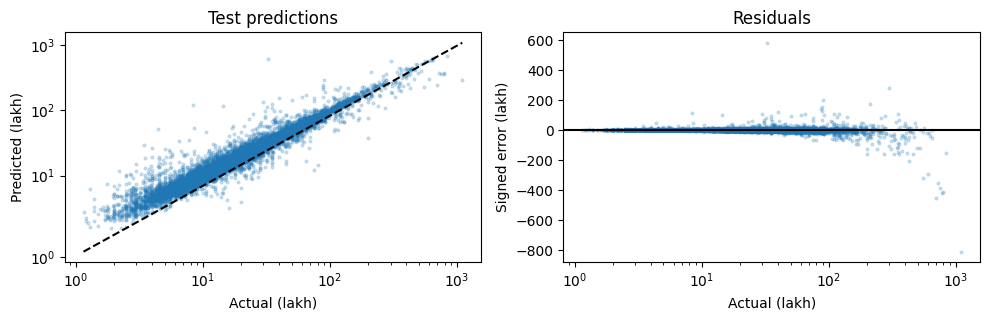

engine_capacity    13.998519
age                11.475753
model               3.193496
feature_count       2.361611
make                2.273862
transmission        1.184527
body_type           1.029964
mileage             0.789868
engine_type         0.774274
assembly            0.663476
dtype: float64

In [6]:
e=pd.DataFrame({'actual':yt,'predicted':pred,'make':Xt.make,'body_type':Xt.body_type}); e['error']=e.predicted-e.actual; e['abs_error']=e.error.abs(); e['relative_error']=e.abs_error/e.actual*100
e['price_band']=pd.cut(e.actual,[0,10,30,70,np.inf],labels=['<=10','10-30','30-70','>70'])
for g in ['make','body_type','price_band']:
    a=e.groupby(g,observed=True).agg(n=('error','size'),bias=('error','mean'),MAE=('abs_error','mean'),MAPE=('relative_error','mean')).query('n>=30').sort_values('n',ascending=False); display(a.head(12).round(2)); a.to_csv('results/errors_'+g+'.csv')
e.to_csv('results/test_predictions.csv',index=False)
fig,ax=plt.subplots(1,2,figsize=(10,3.3)); ax[0].scatter(e.actual,e.predicted,s=4,alpha=.2); ax[0].set(xscale='log',yscale='symlog',xlabel='Actual (lakh)',ylabel='Predicted (lakh)',title='Test predictions'); lo,hi=e.actual.min(),e.actual.max(); ax[0].plot([lo,hi],[lo,hi],'k--'); ax[1].scatter(e.actual,e.error,s=4,alpha=.2); ax[1].set(xscale='log',xlabel='Actual (lakh)',ylabel='Signed error (lakh)',title='Residuals'); ax[1].axhline(0,color='black'); plt.tight_layout(); plt.savefig('results/test_plot.png',dpi=150); plt.show()
s=Xt.sample(1000,random_state=42); imp=permutation_importance(final,s,yt.loc[s.index],scoring='neg_mean_absolute_error',n_repeats=2,random_state=42)
importance=pd.Series(imp.importances_mean,index=X.columns).sort_values(ascending=False); display(importance.head(10)); importance.to_csv('results/importance.csv')
with open('results/summary.json','w') as f: json.dump({'raw':len(raw),'clean':len(d),'recovered':recovered,'winner':winner,'features':selected,'test':test,'cv':cv.tolist(),'median':float(d.target.median()),'train':len(Xa),'val':len(Xv),'test_n':len(Xt)},f,indent=2)

## Limitations
The dataset describes 2022 asking prices, not current values or completed sales. Random splits may contain similar vehicles or relistings. Accident history, inspection quality, seller type and actual condition are unknown. Rare luxury vehicles and noisy mileage may be difficult to predict. Ordinal category codes and fixed hyperparameters limit the comparison. A later-period test with verified transactions would be more useful for deployment.